In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix)
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import os

In [2]:
# Обучающие данные
!gdown --id 12cZqGF4TCeykpRKHDIE8yirM63rLAa0T
train_df = pd.read_csv('train.csv')

# Тестовые данные (для предсказаний)
!gdown --id 1_3p9NYSyfkLJKmBOItnmRL9YY7z6sNCm
test_df = pd.read_csv('test_features.csv')

print(f"Train: {train_df.shape}")
print(f"Test:  {test_df.shape}")

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=12cZqGF4TCeykpRKHDIE8yirM63rLAa0T
To: /content/train.csv
100% 69.8k/69.8k [00:00<00:00, 2.54MB/s]
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1_3p9NYSyfkLJKmBOItnmRL9YY7z6sNCm
To: /content/test_features.csv
100% 17.4k/17.4k [00:00<00:00, 38.4MB/s]
Train: (800, 19)
Test:  (200, 18)


In [3]:
# Список признаков
numeric_cols = train_df.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols.remove('patient_id')
numeric_cols.remove('prediction')
numeric_cols.remove('Доклинический_риск')

print(f"Признаков: {len(numeric_cols)}")
print(numeric_cols)

# Заполняем пропуски: train — своими средними, test — средними из train
for col in numeric_cols:
    train_df[col] = train_df[col].fillna(train_df[col].mean())
    test_df[col] = test_df[col].fillna(train_df[col].mean())

print(f"\nПропуски в train: {train_df[numeric_cols].isnull().sum().sum()}")
print(f"Пропуски в test:  {test_df[numeric_cols].isnull().sum().sum()}")

Признаков: 16
['Возраст', 'Пол_мужской', 'ИМТ', 'Окружность_талии_см', 'САД_мм_рт_ст', 'ДАД_мм_рт_ст', 'Пульсовое_давление', 'Глюкоза_натощак_ммоль_л', 'HbA1c_%', 'ЛПНП_ммоль_л', 'ЛПВП_ммоль_л', 'Триглицериды_ммоль_л', 'СКФ_мл_мин', 'Курение', 'Физическая_активность_мин_нед', 'Статус_глюкозы']

Пропуски в train: 0
Пропуски в test:  0


In [4]:
#Формирование X и y
X = train_df[numeric_cols].values.astype(np.float32)
y = train_df['Доклинический_риск'].values.astype(np.float32).reshape(-1, 1)

print(f"X: {X.shape}, y: {y.shape}")
print(f"Распределение классов: {np.bincount(y.astype(int).flatten())}")

X: (800, 16), y: (800, 1)
Распределение классов: [748  52]


In [5]:
#Разбиение на train/test
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape[0]}, Val: {X_val.shape[0]}")
print(f"Train классы: {np.bincount(y_train.astype(int).flatten())}")
print(f"Val классы:   {np.bincount(y_val.astype(int).flatten())}")

Train: 640, Val: 160
Train классы: [598  42]
Val классы:   [150  10]


In [6]:
#Нормализация признаков
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

print(f"X_train: {X_train.shape}, X_val: {X_val.shape}")
print(f"NaN в X_train: {np.isnan(X_train).sum()}")
print(f"NaN в X_val:   {np.isnan(X_val).sum()}")

X_train: (640, 16), X_val: (160, 16)
NaN в X_train: 0
NaN в X_val:   0


In [7]:
#Преобразование в тензоры
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32)

print(f"X_train_t: {X_train_t.shape}")
print(f"y_train_t: {y_train_t.shape}")

X_train_t: torch.Size([640, 16])
y_train_t: torch.Size([640, 1])


In [8]:
#DataLoader
batch_size = 32
train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

print(f"Батчей в train: {len(train_loader)}")
print(f"Батчей в val:   {len(val_loader)}")

Батчей в train: 20
Батчей в val:   5


In [9]:
#Определение модели FFN
class DiabetesFFN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = DiabetesFFN(X_train.shape[1]).to(device)
print(model)
print(f"Устройство: {device}")

DiabetesFFN(
  (fc1): Linear(in_features=16, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
)
Устройство: cpu


In [10]:
#Функция потерь и оптимизатор
pos_weight = torch.tensor([10.0]).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(f"pos_weight = {pos_weight.item()}")
print(f"Optimizer: Adam, lr=0.001")

pos_weight = 10.0
Optimizer: Adam, lr=0.001


In [11]:
#Цикл обучения
epochs = 15
train_losses, val_losses = [], []

for epoch in range(epochs):
    # --- Train ---
    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X_batch.size(0)
    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # --- Validation ---
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            val_loss += loss.item() * X_batch.size(0)
    epoch_val_loss = val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    print(f"Epoch {epoch+1:2d}/{epochs} — Train Loss: {epoch_train_loss:.4f}, Val Loss: {epoch_val_loss:.4f}")

Epoch  1/15 — Train Loss: 1.0520, Val Loss: 0.9781
Epoch  2/15 — Train Loss: 0.9372, Val Loss: 0.8800
Epoch  3/15 — Train Loss: 0.8108, Val Loss: 0.7873
Epoch  4/15 — Train Loss: 0.6955, Val Loss: 0.7226
Epoch  5/15 — Train Loss: 0.6209, Val Loss: 0.6819
Epoch  6/15 — Train Loss: 0.5616, Val Loss: 0.6433
Epoch  7/15 — Train Loss: 0.5136, Val Loss: 0.6202
Epoch  8/15 — Train Loss: 0.4685, Val Loss: 0.6035
Epoch  9/15 — Train Loss: 0.4811, Val Loss: 0.5811
Epoch 10/15 — Train Loss: 0.4572, Val Loss: 0.5778
Epoch 11/15 — Train Loss: 0.4097, Val Loss: 0.5837
Epoch 12/15 — Train Loss: 0.3911, Val Loss: 0.5944
Epoch 13/15 — Train Loss: 0.3832, Val Loss: 0.5944
Epoch 14/15 — Train Loss: 0.3767, Val Loss: 0.6148
Epoch 15/15 — Train Loss: 0.3304, Val Loss: 0.6359


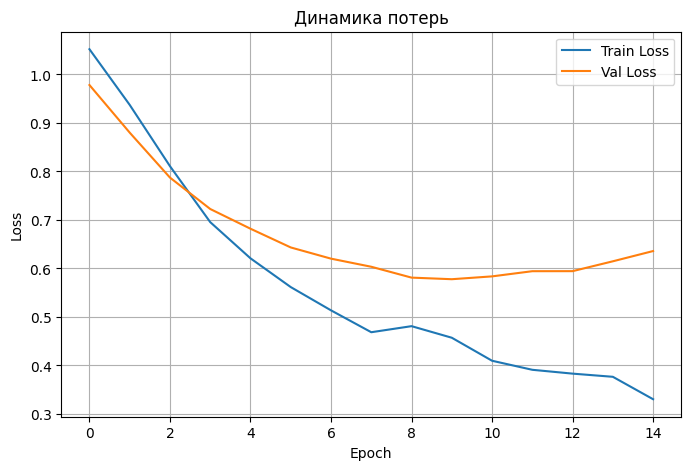

In [12]:
# График потерь
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Динамика потерь')
plt.legend()
plt.grid(True)
plt.show()

In [13]:
#Оценка модели
model.eval()
y_pred_prob = []
y_true = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)
        outputs = model(X_batch)
        probs = torch.sigmoid(outputs)
        y_pred_prob.extend(probs.cpu().numpy().flatten())
        y_true.extend(y_batch.numpy().flatten())

y_pred_prob = np.array(y_pred_prob)
y_true = np.array(y_true)

print(f"Диапазон вероятностей: {y_pred_prob.min():.4f} — {y_pred_prob.max():.4f}")
print(f"Средняя вероятность: {y_pred_prob.mean():.4f}")
print(f"Реально класса 1: {(y_true == 1).sum()}")
print(f"Вероятности для класса 1:")
print(np.sort(y_pred_prob[y_true == 1]))
print(f"\nROC-AUC: {roc_auc_score(y_true, y_pred_prob):.4f}")

Диапазон вероятностей: 0.0000 — 0.9833
Средняя вероятность: 0.1418
Реально класса 1: 10
Вероятности для класса 1:
[0.04174366 0.14840974 0.4130252  0.6695921  0.6857898  0.7306908
 0.7821317  0.7824806  0.93227524 0.9833273 ]

ROC-AUC: 0.9207


In [14]:
#Подбор порога валидации
print("ПОДБОР ПОРОГА НА ВАЛИДАЦИИ")

best_f1 = 0
best_threshold = 0.5

for threshold in [0.3, 0.4, 0.5, 0.55, 0.6, 0.65, 0.7]:
    y_pred = (y_pred_prob >= threshold).astype(int)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0,0,0,0)

    marker = " ← ЛУЧШИЙ" if f1 > best_f1 else ""
    print(f"Порог {threshold:.2f}: TP={tp}, FN={fn}, FP={fp} | F1={f1:.4f}, Prec={prec:.4f}, Rec={rec:.4f}{marker}")

    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold

print(f"\nЛучший порог на val: {best_threshold} (F1 = {best_f1:.4f})")

ПОДБОР ПОРОГА НА ВАЛИДАЦИИ
Порог 0.30: TP=8, FN=2, FP=23 | F1=0.3902, Prec=0.2581, Rec=0.8000 ← ЛУЧШИЙ
Порог 0.40: TP=8, FN=2, FP=16 | F1=0.4706, Prec=0.3333, Rec=0.8000 ← ЛУЧШИЙ
Порог 0.50: TP=7, FN=3, FP=11 | F1=0.5000, Prec=0.3889, Rec=0.7000 ← ЛУЧШИЙ
Порог 0.55: TP=7, FN=3, FP=7 | F1=0.5833, Prec=0.5000, Rec=0.7000 ← ЛУЧШИЙ
Порог 0.60: TP=7, FN=3, FP=7 | F1=0.5833, Prec=0.5000, Rec=0.7000
Порог 0.65: TP=7, FN=3, FP=7 | F1=0.5833, Prec=0.5000, Rec=0.7000
Порог 0.70: TP=5, FN=5, FP=5 | F1=0.5000, Prec=0.5000, Rec=0.5000

Лучший порог на val: 0.55 (F1 = 0.5833)


In [15]:
# Признаки test
X_test_sub = test_df[numeric_cols].values.astype(np.float32)
X_test_sub = scaler.transform(X_test_sub)
X_test_sub_t = torch.tensor(X_test_sub, dtype=torch.float32).to(device)

# Предсказания
model.eval()
with torch.no_grad():
    outputs = model(X_test_sub_t)
    probs_test = torch.sigmoid(outputs).cpu().numpy().flatten()

y_true_test = test_df['Доклинический_риск'].values

# Проверка NaN
print(f"NaN в probs_test: {np.isnan(probs_test).sum()}")
print(f"Диапазон: {probs_test.min():.4f} — {probs_test.max():.4f}")
print(f"Среднее:  {probs_test.mean():.4f}")

# ROC-AUC на test
print(f"\nROC-AUC на test: {roc_auc_score(y_true_test, probs_test):.4f}")

NaN в probs_test: 0
Диапазон: 0.0000 — 0.9839
Среднее:  0.1263

ROC-AUC на test: 0.8947


In [16]:
print("ПОДБОР ПОРОГА НА TEST_FEATURES")
best_f1_test = 0
best_threshold_test = 0.5

for threshold in [0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    y_pred = (probs_test >= threshold).astype(int)
    f1 = f1_score(y_true_test, y_pred, zero_division=0)
    prec = precision_score(y_true_test, y_pred, zero_division=0)
    rec = recall_score(y_true_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_true_test, y_pred)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0,0,0,0)

    marker = " ← ЛУЧШИЙ" if f1 > best_f1_test else ""
    print(f"Порог {threshold:.2f}: TP={tp}, FN={fn}, FP={fp} | F1={f1:.4f}, Prec={prec:.4f}, Rec={rec:.4f}{marker}")

    if f1 > best_f1_test:
        best_f1_test = f1
        best_threshold_test = threshold

print(f"\nЛучший порог на test: {best_threshold_test} (F1 = {best_f1_test:.4f})")

ПОДБОР ПОРОГА НА TEST_FEATURES
Порог 0.05: TP=9, FN=0, FP=54 | F1=0.2500, Prec=0.1429, Rec=1.0000 ← ЛУЧШИЙ
Порог 0.10: TP=9, FN=0, FP=46 | F1=0.2812, Prec=0.1636, Rec=1.0000 ← ЛУЧШИЙ
Порог 0.15: TP=9, FN=0, FP=36 | F1=0.3333, Prec=0.2000, Rec=1.0000 ← ЛУЧШИЙ
Порог 0.20: TP=8, FN=1, FP=32 | F1=0.3265, Prec=0.2000, Rec=0.8889
Порог 0.30: TP=6, FN=3, FP=23 | F1=0.3158, Prec=0.2069, Rec=0.6667
Порог 0.40: TP=4, FN=5, FP=21 | F1=0.2353, Prec=0.1600, Rec=0.4444
Порог 0.50: TP=3, FN=6, FP=17 | F1=0.2069, Prec=0.1500, Rec=0.3333
Порог 0.60: TP=2, FN=7, FP=14 | F1=0.1600, Prec=0.1250, Rec=0.2222
Порог 0.70: TP=2, FN=7, FP=11 | F1=0.1818, Prec=0.1538, Rec=0.2222

Лучший порог на test: 0.15 (F1 = 0.3333)


In [27]:
best_threshold = 0.15
y_pred_final = (probs_test >= best_threshold).astype(int)

print(f"ФИНАЛЬНЫЕ МЕТРИКИ НА TEST (порог {best_threshold})")
print(f"Accuracy:  {accuracy_score(y_true_test, y_pred_final):.4f}")
print(f"Precision: {precision_score(y_true_test, y_pred_final, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_true_test, y_pred_final, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_true_test, y_pred_final, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_true_test, probs_test):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_true_test, y_pred_final))

# Проверка распределения
print(f"\nРаспределение предсказаний:")
print(f"  Класс 0: {(y_pred_final == 0).sum()}")
print(f"  Класс 1: {(y_pred_final == 1).sum()}")
print(f"  Всего: {len(y_pred_final)}")

ФИНАЛЬНЫЕ МЕТРИКИ НА TEST (порог 0.15)
Accuracy:  0.8200
Precision: 0.2000
Recall:    1.0000
F1-score:  0.3333
ROC-AUC:   0.8947

Confusion Matrix:
[[155  36]
 [  0   9]]

Распределение предсказаний:
  Класс 0: 155
  Класс 1: 45
  Всего: 200


In [28]:
#outputs/task1_predictions.csv
import os

best_threshold = 0.15
predictions = (probs_test >= best_threshold).astype(int)

output_df = pd.DataFrame({
    'patient_id': test_df['patient_id'],
    'prediction': predictions
})

os.makedirs('outputs', exist_ok=True)
output_df.to_csv('outputs/task1_predictions.csv', index=False)

print(f"Сохр.: outputs/task1_predictions.csv")
print(f"Строк: {len(output_df)}")
print(f"Колонки: {output_df.columns.tolist()}")
print(f"\nРаспределение предсказаний:")
print(output_df['prediction'].value_counts())
print(f"\nПервые 10 строк:")
print(output_df.head(10))

Сохр.: outputs/task1_predictions.csv
Строк: 200
Колонки: ['patient_id', 'prediction']

Распределение предсказаний:
prediction
0    155
1     45
Name: count, dtype: int64

Первые 10 строк:
   patient_id  prediction
0           2           0
1           3           0
2           8           0
3          18           0
4          19           0
5          20           0
6          28           1
7          29           0
8          37           0
9          43           0


In [29]:
from google.colab import files
files.download('outputs/task1_predictions.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>